### Word2Vec Implementation from Scratch

# Introduction
 Word2Vec is a popular technique for word embeddings, which captures the meaning of words by placing them in a continuous vector space.
 In this exercise, you will implement Word2Vec using NumPy and complete the missing parts of the code.
We will represent each word as a one-hot vector, meaning each word in the vocabulary is mapped to a unique binary vector with only one active (1) position.

import necessary libraries

In [11]:
import numpy as np
from collections import defaultdict
import tensorflow as tf

In [12]:
sentences = [
    'cat chases mouse',
    'cat catches mouse',
    'cat eats mouse',
    'mouse runs into hole',
    'cat says bad words',
    'cat and mouse are pals',
    'cat and mouse are chums',
    'mouse stores food in hole',
    'cat stores food in house',
    'mouse sleeps in hole',
    'cat sleeps in house',
    'cat and mouse are buddies',
    'mouse lives in hole',
    'cat lives in house'
]

In [13]:
# def get_vocab(data):
#     word2idx = {}
#     idx2word = {}

#     for sentence in data:
#         for word in sentence.split():
#             if word not in word2idx:
#                 index = len(word2idx) + 1  # Start indexing from 1
#                 word2idx[word] = index
#                 idx2word[index] = word

#     vocab_size = len(word2idx) + 1  # Including padding index 0
#     return vocab_size, word2idx, idx2word

In [14]:
# finds total of the unique vocabs
# assigns unique id to each word in corpus

def get_vocab(data):
    i = 1
    word2idx = dict()
    idx2word = dict()
    temp = set()
    
    # Loop over all sentences
    for sentence in data:
        # Split each sentence into words
        for word in sentence.split():
            if word not in temp:
                temp.add(word)
                word2idx[word] = i  # Mapping word to index
                idx2word[i] = word  # Mapping index to word
                i += 1
    
    return i, word2idx, idx2word

vocab_size, word2idx, idx2word = get_vocab(sentences)

In [15]:
print("vocab size", vocab_size)
print("Word to Index Mapping:", word2idx)
print("Index to Word Mapping:", idx2word)

vocab size 23
Word to Index Mapping: {'cat': 1, 'chases': 2, 'mouse': 3, 'catches': 4, 'eats': 5, 'runs': 6, 'into': 7, 'hole': 8, 'says': 9, 'bad': 10, 'words': 11, 'and': 12, 'are': 13, 'pals': 14, 'chums': 15, 'stores': 16, 'food': 17, 'in': 18, 'house': 19, 'sleeps': 20, 'buddies': 21, 'lives': 22}
Index to Word Mapping: {1: 'cat', 2: 'chases', 3: 'mouse', 4: 'catches', 5: 'eats', 6: 'runs', 7: 'into', 8: 'hole', 9: 'says', 10: 'bad', 11: 'words', 12: 'and', 13: 'are', 14: 'pals', 15: 'chums', 16: 'stores', 17: 'food', 18: 'in', 19: 'house', 20: 'sleeps', 21: 'buddies', 22: 'lives'}


In [16]:
print(word2idx['mouse'])
print(idx2word[3])

3
mouse


In [17]:
# Function to get previous words in the window
def prev_words(i, doc, window_size):
    out = []
    for index in range(i - window_size, i):
        if index >= 0:
            out.append(word2idx[doc[index]])
        else:
            out.append(0)  # 0 = <PAD>
    return out

# Function to get next words in the window
def next_words(i, doc, window_size):
    out = []
    for index in range(i + 1, i + window_size + 1, 1):
        if index < len(doc):
            out.append(word2idx[doc[index]])
        else:
            out.append(0)  # 0 = <PAD>
    return out

In [18]:
def get_training_data(sentences, window_size=6):
    X = []
    y = []
    for sentence in sentences:
        xi = []
        yi = []
        sentence = sentence.split()
        for index, word in enumerate(sentence):
            prev = prev_words(index, sentence, window_size//2)
            next = next_words(index, sentence, window_size//2)
            assert len(prev) == len(next)
            xi.append(prev + next)
            yi.append([word2idx[word]])
        X.extend(xi)
        y.extend(yi)
    return X, y

window_size = 5
X, y = get_training_data(sentences, window_size)

print(len(X))

58


In [19]:
print(type(X))
print(type(y))

<class 'list'>
<class 'list'>


In [20]:
print(X)
print(y)

[[0, 0, 2, 3], [0, 1, 3, 0], [1, 2, 0, 0], [0, 0, 4, 3], [0, 1, 3, 0], [1, 4, 0, 0], [0, 0, 5, 3], [0, 1, 3, 0], [1, 5, 0, 0], [0, 0, 6, 7], [0, 3, 7, 8], [3, 6, 8, 0], [6, 7, 0, 0], [0, 0, 9, 10], [0, 1, 10, 11], [1, 9, 11, 0], [9, 10, 0, 0], [0, 0, 12, 3], [0, 1, 3, 13], [1, 12, 13, 14], [12, 3, 14, 0], [3, 13, 0, 0], [0, 0, 12, 3], [0, 1, 3, 13], [1, 12, 13, 15], [12, 3, 15, 0], [3, 13, 0, 0], [0, 0, 16, 17], [0, 3, 17, 18], [3, 16, 18, 8], [16, 17, 8, 0], [17, 18, 0, 0], [0, 0, 16, 17], [0, 1, 17, 18], [1, 16, 18, 19], [16, 17, 19, 0], [17, 18, 0, 0], [0, 0, 20, 18], [0, 3, 18, 8], [3, 20, 8, 0], [20, 18, 0, 0], [0, 0, 20, 18], [0, 1, 18, 19], [1, 20, 19, 0], [20, 18, 0, 0], [0, 0, 12, 3], [0, 1, 3, 13], [1, 12, 13, 21], [12, 3, 21, 0], [3, 13, 0, 0], [0, 0, 22, 18], [0, 3, 18, 8], [3, 22, 8, 0], [22, 18, 0, 0], [0, 0, 22, 18], [0, 1, 18, 19], [1, 22, 19, 0], [22, 18, 0, 0]]
[[1], [2], [3], [1], [4], [3], [1], [5], [3], [3], [6], [7], [8], [1], [9], [10], [11], [1], [12], [3], [13]

In [21]:
print(X[24])
print(y[24])

[1, 12, 13, 15]
[3]


In [22]:
print([idx2word[i] for i in X[24]])
print([idx2word[i] for i in y[24]])

['cat', 'and', 'are', 'chums']
['mouse']


In [23]:
X = np.array(X)
# Fixing the shape of y
y = np.array(y).flatten()

In [24]:
print(type(X))
print(type(y))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [25]:
print(X)
print(y)

[[ 0  0  2  3]
 [ 0  1  3  0]
 [ 1  2  0  0]
 [ 0  0  4  3]
 [ 0  1  3  0]
 [ 1  4  0  0]
 [ 0  0  5  3]
 [ 0  1  3  0]
 [ 1  5  0  0]
 [ 0  0  6  7]
 [ 0  3  7  8]
 [ 3  6  8  0]
 [ 6  7  0  0]
 [ 0  0  9 10]
 [ 0  1 10 11]
 [ 1  9 11  0]
 [ 9 10  0  0]
 [ 0  0 12  3]
 [ 0  1  3 13]
 [ 1 12 13 14]
 [12  3 14  0]
 [ 3 13  0  0]
 [ 0  0 12  3]
 [ 0  1  3 13]
 [ 1 12 13 15]
 [12  3 15  0]
 [ 3 13  0  0]
 [ 0  0 16 17]
 [ 0  3 17 18]
 [ 3 16 18  8]
 [16 17  8  0]
 [17 18  0  0]
 [ 0  0 16 17]
 [ 0  1 17 18]
 [ 1 16 18 19]
 [16 17 19  0]
 [17 18  0  0]
 [ 0  0 20 18]
 [ 0  3 18  8]
 [ 3 20  8  0]
 [20 18  0  0]
 [ 0  0 20 18]
 [ 0  1 18 19]
 [ 1 20 19  0]
 [20 18  0  0]
 [ 0  0 12  3]
 [ 0  1  3 13]
 [ 1 12 13 21]
 [12  3 21  0]
 [ 3 13  0  0]
 [ 0  0 22 18]
 [ 0  3 18  8]
 [ 3 22  8  0]
 [22 18  0  0]
 [ 0  0 22 18]
 [ 0  1 18 19]
 [ 1 22 19  0]
 [22 18  0  0]]
[ 1  2  3  1  4  3  1  5  3  3  6  7  8  1  9 10 11  1 12  3 13 14  1 12
  3 13 15  3 16 17 18  8  1 16 17 18 19  3 20 18  8  1 2

In [26]:
# Define the model

# dimention
embed_size = 10

model = tf.keras.models.Sequential()
model.add(tf.keras.layers.Embedding(vocab_size, embed_size, name='embedding'))
model.add(tf.keras.layers.GlobalAveragePooling1D())
model.add(tf.keras.layers.Dense(vocab_size, activation='softmax'))

# Compile the model
model.compile(optimizer='Adam', loss='sparse_categorical_crossentropy')

# Train the model
model.fit(X, y, epochs=10, batch_size=6)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3.13093
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 3.1160 
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 895us/step - loss: 3.1096
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 723us/step - loss: 3.1043
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 778us/step - loss: 3.0906 
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3.0857 
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 892us/step - loss: 3.0586
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 947us/step - loss: 3.0518
Epoch 9/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 3.0310  
Epoch 10/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 716us/step - loss: 3.0311


In [27]:
word = 'mouse'
input_vec = tf.convert_to_tensor([word2idx[word]])
model.get_layer('embedding')(input_vec).numpy().tolist()

[[-0.004653357435017824,
  -0.03706594929099083,
  -0.042937200516462326,
  -0.03061709739267826,
  0.0671292245388031,
  -0.04304193705320358,
  0.042547982186079025,
  -0.06911451369524002,
  0.06435927748680115,
  -0.0105498768389225]]

In [28]:
word2vec = []
for word, word_indx in word2idx.items():
    input_vec = tf.convert_to_tensor([word2idx[word]])
    vec = model.get_layer('embedding')(input_vec).numpy().tolist()[0]
    word2vec.append((word, vec))

In [29]:
print(len(word2vec))
print(word2vec)

word2vec[11]

22
[('cat', [-0.06747177243232727, -0.12151528894901276, 0.07448086887598038, 0.00910788681358099, 0.02314835414290428, -0.08995703607797623, -0.05041660740971565, 0.06135222688317299, 0.04788416996598244, 0.032161351293325424]), ('chases', [0.017928915098309517, -0.030779849737882614, 0.03837846964597702, -0.07888191193342209, -0.012142256833612919, -0.05399837717413902, 0.03350931406021118, -0.006238730624318123, 0.04965437948703766, -0.014658449217677116]), ('mouse', [-0.004653357435017824, -0.03706594929099083, -0.042937200516462326, -0.03061709739267826, 0.0671292245388031, -0.04304193705320358, 0.042547982186079025, -0.06911451369524002, 0.06435927748680115, -0.0105498768389225]), ('catches', [-0.0696733146905899, -0.020705142989754677, 0.062402285635471344, -0.09458203613758087, 0.050025343894958496, -0.04144729673862457, -0.0016631080070510507, 0.002035281853750348, 0.034213125705718994, -0.004236996173858643]), ('eats', [0.0060773068107664585, -0.015322775579988956, 0.08369495

('and',
 [-0.10491564869880676,
  -0.02153996005654335,
  -0.02723478339612484,
  -0.13824746012687683,
  0.07588622719049454,
  -0.12571372091770172,
  0.03768391162157059,
  -0.06000155583024025,
  0.11904540657997131,
  -0.13583314418792725])

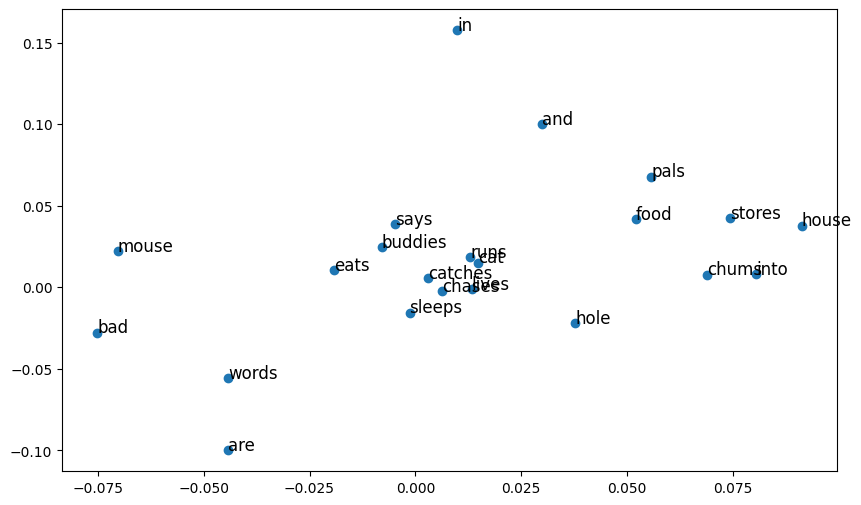

In [207]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plotting all points from word2vec
plt.scatter([i[1][0] for i in word2vec], [i[1][1] for i in word2vec])

# Annotating each point with the corresponding word
for item in word2vec:
    word = item[0]
    plt.text(item[1][0], item[1][1], word, fontdict={'fontsize': 12})

plt.show()